<a href="https://colab.research.google.com/github/HamsMSaidam/QUALIFY/blob/main/QUALIFY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier

from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)

RAW = "../data/raw"
OUT = "../data/processed"
FIG = "../figures"
RES = "../results"

for folder in [OUT, FIG, RES]:
    os.makedirs(folder, exist_ok=True)

RANDOM_STATE = 42

TARGET = "quality_of_sleep"
CLASS = "sleep_quality_class"
CLASS_ORDER = ["low", "medium", "high"]

NUM_FEATURES = [
    "age", "daily_steps", "heart_rate",
    "physical_activity_level", "sleep_duration", "stress_level"
]

CAT_FEATURES = ["gender", "bmi_category"]

FEATURES = [
    "age", "gender", "bmi_category", "daily_steps",
    "heart_rate", "physical_activity_level",
    "sleep_duration", "stress_level"
]

In [12]:
df = pd.read_csv(
    f"Sleep_health_and_lifestyle_dataset.csv",
    keep_default_na=False,
    na_values=[""]
)

print("Original shape:", df.shape)

Original shape: (374, 13)


In [14]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^\w]+", "_", regex=True)
    .str.strip("_")
)

# Standardize categorical text
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip().str.lower()

# Make BMI categories consistent
df["bmi_category"] = df["bmi_category"].replace({
    "normal weight": "normal"
})

print("Columns:", df.columns.tolist())

Columns: ['person_id', 'gender', 'age', 'occupation', 'sleep_duration', 'quality_of_sleep', 'physical_activity_level', 'stress_level', 'bmi_category', 'blood_pressure', 'heart_rate', 'daily_steps', 'sleep_disorder']


In [15]:
df = df.drop(columns=["person_id"])
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print(df.head())

Shape after removing duplicates: (132, 12)
  gender  age            occupation  sleep_duration  quality_of_sleep  \
0   male   27     software engineer             6.1                 6   
1   male   28                doctor             6.2                 6   
2   male   28  sales representative             5.9                 4   
3   male   28     software engineer             5.9                 4   
4   male   29               teacher             6.3                 6   

   physical_activity_level  stress_level bmi_category blood_pressure  \
0                       42             6   overweight         126/83   
1                       60             8       normal         125/80   
2                       30             8        obese         140/90   
3                       30             8        obese         140/90   
4                       40             7        obese         140/90   

   heart_rate  daily_steps sleep_disorder  
0          77         4200           none

In [16]:
print("Missing values:\n", df.isna().sum())

df = df.dropna(subset=[TARGET]).copy()

invalid = (
    (df["age"] < 18) |
    (df["heart_rate"] > 120) |
    (df["sleep_duration"] > 12)
)

print("Invalid rows:", invalid.sum())

df = df.loc[~invalid].reset_index(drop=True)

print("Final shape:", df.shape)

Missing values:
 gender                     0
age                        0
occupation                 0
sleep_duration             0
quality_of_sleep           0
physical_activity_level    0
stress_level               0
bmi_category               0
blood_pressure             0
heart_rate                 0
daily_steps                0
sleep_disorder             0
dtype: int64
Invalid rows: 0
Final shape: (132, 12)


In [17]:
df[CLASS] = pd.cut(
    df[TARGET],
    bins=[-np.inf, 6, 8, np.inf],
    labels=CLASS_ORDER,
    right=False
).astype(str)

print(df[TARGET].describe())
print("\nClass counts:")
print(df[CLASS].value_counts().reindex(CLASS_ORDER))

count    132.000000
mean       7.151515
std        1.269037
min        4.000000
25%        6.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: quality_of_sleep, dtype: float64

Class counts:
sleep_quality_class
low       10
medium    65
high      57
Name: count, dtype: int64


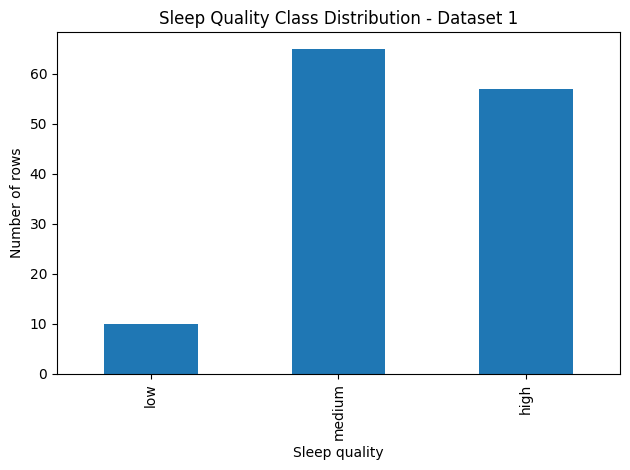

In [18]:
df[CLASS].value_counts().reindex(CLASS_ORDER).plot(kind="bar")

plt.title("Sleep Quality Class Distribution - Dataset 1")
plt.xlabel("Sleep quality")
plt.ylabel("Number of rows")
plt.tight_layout()
plt.savefig(f"{FIG}/label_distribution.png", dpi=150)
plt.show()

In [19]:
train_df, test_df = train_test_split(
    df[FEATURES + [TARGET, CLASS]],
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=df[CLASS]
)

X_train = train_df[FEATURES]
X_test = test_df[FEATURES]

y_reg_train = train_df[TARGET]
y_reg_test = test_df[TARGET]

y_clf_train = train_df[CLASS]
y_clf_test = test_df[CLASS]

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (105, 8)
Testing set: (27, 8)


In [20]:
def build_preprocessor():

    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            drop="if_binary",
            sparse_output=False
        ))
    ])

    return ColumnTransformer([
        ("num", numeric, NUM_FEATURES),
        ("cat", categorical, CAT_FEATURES)
    ])


def pipe(model):
    return Pipeline([
        ("prep", build_preprocessor()),
        ("model", model)
    ])

In [21]:
df.to_csv(f"{OUT}/dataset1_clean.csv", index=False)
train_df.to_csv(f"{OUT}/train.csv", index=False)
test_df.to_csv(f"{OUT}/test.csv", index=False)

In [22]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

reg_models = {
    "Mean Predictor": pipe(DummyRegressor(strategy="mean")),
    "Linear Regression": pipe(LinearRegression())
}

reg_rows = []

for name, model in reg_models.items():
    scores = cross_validate(
        model, X_train, y_reg_train,
        cv=kf, scoring=scoring
    )

    reg_rows.append({
        "model": name,
        "cv_r2": scores["test_r2"].mean(),
        "cv_mae": -scores["test_mae"].mean(),
        "cv_rmse": -scores["test_rmse"].mean()
    })

# Tune Ridge Regression
ridge_grid = GridSearchCV(
    pipe(Ridge()),
    {"model__alpha": [0.01, 0.1, 1, 10, 30, 100]},
    cv=kf,
    scoring="r2"
)

ridge_grid.fit(X_train, y_reg_train)
best_ridge = ridge_grid.best_estimator_

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])

scores = cross_validate(
    best_ridge, X_train, y_reg_train,
    cv=kf, scoring=scoring
)

reg_rows.append({
    "model": "Ridge Regression",
    "cv_r2": scores["test_r2"].mean(),
    "cv_mae": -scores["test_mae"].mean(),
    "cv_rmse": -scores["test_rmse"].mean()
})

reg_cv = pd.DataFrame(reg_rows).round(3)
print(reg_cv)

Best Ridge alpha: 1
               model  cv_r2  cv_mae  cv_rmse
0     Mean Predictor -0.043   1.061    1.251
1  Linear Regression  0.880   0.311    0.401
2   Ridge Regression  0.884   0.309    0.393


In [23]:
reg_models["Ridge Regression"] = best_ridge

reg_test_rows = []

for name, model in reg_models.items():
    model.fit(X_train, y_reg_train)
    pred = model.predict(X_test)

    reg_test_rows.append({
        "model": name,
        "test_r2": r2_score(y_reg_test, pred),
        "test_mae": mean_absolute_error(y_reg_test, pred),
        "test_rmse": np.sqrt(mean_squared_error(y_reg_test, pred))
    })

reg_test = pd.DataFrame(reg_test_rows).round(3)
print(reg_test)

               model  test_r2  test_mae  test_rmse
0     Mean Predictor   -0.010     1.088      1.329
1  Linear Regression    0.929     0.265      0.352
2   Ridge Regression    0.929     0.272      0.352


In [24]:
skf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

clf_models = {
    "Majority Class": pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": pipe(LogisticRegression(max_iter=2000))
}

clf_scoring = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro"
}

clf_rows = []

for name, model in clf_models.items():
    scores = cross_validate(
        model, X_train, y_clf_train,
        cv=skf, scoring=clf_scoring
    )

    clf_rows.append({
        "model": name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_f1_macro": scores["test_f1_macro"].mean()
    })

# Tune Logistic Regression
logit_grid = GridSearchCV(
    pipe(LogisticRegression(max_iter=2000)),
    {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },
    cv=skf,
    scoring="f1_macro"
)

logit_grid.fit(X_train, y_clf_train)
best_logit = logit_grid.best_estimator_

print("Best Logistic Regression parameters:", logit_grid.best_params_)

scores = cross_validate(
    best_logit, X_train, y_clf_train,
    cv=skf, scoring=clf_scoring
)

clf_rows.append({
    "model": "Tuned Logistic Regression",
    "cv_accuracy": scores["test_accuracy"].mean(),
    "cv_f1_macro": scores["test_f1_macro"].mean()
})

clf_cv = pd.DataFrame(clf_rows).round(3)
print(clf_cv)

Best Logistic Regression parameters: {'model__C': 10, 'model__class_weight': None}
                       model  cv_accuracy  cv_f1_macro
0             Majority Class        0.495        0.221
1        Logistic Regression        0.914        0.864
2  Tuned Logistic Regression        0.933        0.923


In [25]:
clf_models["Tuned Logistic Regression"] = best_logit

clf_test_rows = []

for name, model in clf_models.items():
    model.fit(X_train, y_clf_train)
    pred = model.predict(X_test)

    clf_test_rows.append({
        "model": name,
        "test_accuracy": accuracy_score(y_clf_test, pred),
        "test_f1_macro": f1_score(
            y_clf_test, pred, average="macro"
        )
    })

clf_test = pd.DataFrame(clf_test_rows).round(3)
print(clf_test)

                       model  test_accuracy  test_f1_macro
0             Majority Class          0.481          0.217
1        Logistic Regression          0.889          0.616
2  Tuned Logistic Regression          0.926          0.850


              precision    recall  f1-score   support

         low      1.000     0.500     0.667         2
      medium      0.923     0.923     0.923        13
        high      0.923     1.000     0.960        12

    accuracy                          0.926        27
   macro avg      0.949     0.808     0.850        27
weighted avg      0.929     0.926     0.920        27



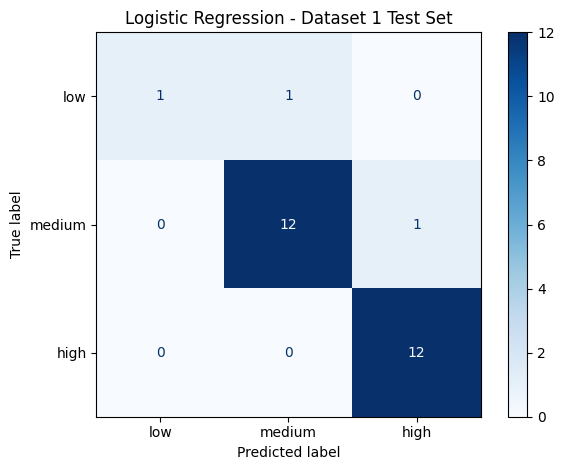

In [26]:
pred = best_logit.predict(X_test)

print(classification_report(
    y_clf_test, pred,
    labels=CLASS_ORDER,
    digits=3
))

ConfusionMatrixDisplay.from_predictions(
    y_clf_test, pred,
    labels=CLASS_ORDER,
    cmap="Blues"
)

plt.title("Logistic Regression - Dataset 1 Test Set")
plt.tight_layout()
plt.savefig(f"{FIG}/baseline_logistic_confusion_matrix.png", dpi=150)
plt.show()

In [27]:
results = pd.concat([
    reg_cv.merge(reg_test, on="model"),
    clf_cv.merge(clf_test, on="model")
], ignore_index=True)

results.to_csv(f"{RES}/baseline_results.csv", index=False)

joblib.dump(best_ridge, f"{OUT}/best_ridge_model.joblib")
joblib.dump(best_logit, f"{OUT}/best_logistic_model.joblib")

print(results.round(3))
print("\nResults saved in:", RES)
print("Models saved in:", OUT)

                       model  cv_r2  cv_mae  cv_rmse  test_r2  test_mae  \
0             Mean Predictor -0.043   1.061    1.251   -0.010     1.088   
1          Linear Regression  0.880   0.311    0.401    0.929     0.265   
2           Ridge Regression  0.884   0.309    0.393    0.929     0.272   
3             Majority Class    NaN     NaN      NaN      NaN       NaN   
4        Logistic Regression    NaN     NaN      NaN      NaN       NaN   
5  Tuned Logistic Regression    NaN     NaN      NaN      NaN       NaN   

   test_rmse  cv_accuracy  cv_f1_macro  test_accuracy  test_f1_macro  
0      1.329          NaN          NaN            NaN            NaN  
1      0.352          NaN          NaN            NaN            NaN  
2      0.352          NaN          NaN            NaN            NaN  
3        NaN        0.495        0.221          0.481          0.217  
4        NaN        0.914        0.864          0.889          0.616  
5        NaN        0.933        0.923          

In [28]:
import os

print("Current directory:", os.getcwd())
print("Results folder:", os.path.abspath(RES))
print("Files in results folder:", os.listdir(RES))

Current directory: /content
Results folder: /results
Files in results folder: ['baseline_results.csv']


In [29]:
from google.colab import files

files.download(f"{RES}/baseline_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
display(pd.read_csv(f"{RES}/baseline_results.csv"))

,model,cv_r2,cv_mae,cv_rmse,test_r2,test_mae,test_rmse,cv_accuracy,cv_f1_macro,test_accuracy,test_f1_macro
0,Mean Predictor,-0.043,1.061,1.251,-0.010,1.088,1.329,NaN,NaN,NaN,NaN
1,Linear Regression,0.880,0.311,0.401,0.929,0.265,0.352,NaN,NaN,NaN,NaN
2,Ridge Regression,0.884,0.309,0.393,0.929,0.272,0.352,NaN,NaN,NaN,NaN
3,Majority Class,NaN,NaN,NaN,NaN,NaN,NaN,0.495,0.221,0.481,0.217
4,Logistic Regression,NaN,NaN,NaN,NaN,NaN,NaN,0.914,0.864,0.889,0.616
5,Tuned Logistic Regression,NaN,NaN,NaN,NaN,NaN,NaN,0.933,0.923,0.926,0.850
